# ScholarTrack — Student At-Risk Detector (Very Simple CNN)

Built to follow your **CE24MDM305 – Foundations of GenAI** course plan:

| Course topic (your faculty) | Where it appears here |
|---|---|
| Steps in training an ANN | Steps 1–6 below |
| Parameters & hyperparameters | Step 5 (`EPOCHS`, `BATCH_SIZE`, `FILTERS`) |
| CNN (Unit 2) | Step 4 (`Conv1D` + `Flatten` + `Dense`) |
| Python & TensorFlow 2: preprocessing, cleaning, visualising data | Steps 1, 2, 3 |

**Problem:** 10 subjects, marks and attendance recorded 6 times in a semester.
**Rule:** if the marks are **falling and end below 75%** *and* the attendance is **falling and ends below 75%** → **At Risk**, otherwise → **Doing well**.
**Output:** 2 neurons → `[doing well, at risk]`.

## Step 0 — Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

np.random.seed(0)
tf.random.set_seed(0)

I0000 00:00:1792168883.480501     504 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792168883.540272     504 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792168884.988664     504 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 1 — Create the dataset
For every student we make a table of shape **6 assessments × 10 subjects** for marks and the same for attendance.
Each student gets a random start value and a random change (up or down) over the semester.

In [ ]:
N = 2000          # number of students
T = 6             # number of assessments in the semester
S = 10            # number of subjects

marks = np.zeros((N, T, S))
attendance = np.zeros((N, T, S))
steps = np.arange(T)

for i in range(N):
    m_start, m_change = np.random.uniform(60, 95), np.random.uniform(-25, 10)
    a_start, a_change = np.random.uniform(65, 98), np.random.uniform(-25, 8)
    for s in range(S):
        marks[i, :, s]      = m_start + np.random.normal(0, 4) + m_change * steps / (T - 1) + np.random.normal(0, 2, T)
        attendance[i, :, s] = a_start + np.random.normal(0, 3) + a_change * steps / (T - 1) + np.random.normal(0, 1.5, T)

marks = np.clip(marks, 0, 100)
attendance = np.clip(attendance, 0, 100)
print('marks shape      :', marks.shape, '(students, assessments, subjects)')
print('attendance shape :', attendance.shape)

marks shape      : (2000, 6, 10) (students, assessments, subjects)
attendance shape : (2000, 6, 10)


## Step 2 — Make the labels (apply the rule)
Take the **average of the 10 subjects** for each assessment, then check:
- is the last value **lower than the first** (falling)?
- is the last value **below 75**?

Label `1` = at risk (both marks and attendance), label `0` = doing well.

In [ ]:
avg_marks = marks.mean(axis=2)            # shape (N, T)
avg_att   = attendance.mean(axis=2)       # shape (N, T)

marks_bad = (avg_marks[:, -1] < avg_marks[:, 0]) & (avg_marks[:, -1] < 75)
att_bad   = (avg_att[:, -1]   < avg_att[:, 0])   & (avg_att[:, -1]   < 75)

y = (marks_bad & att_bad).astype(int)     # 1 = at risk, 0 = doing well
print('Doing well:', (y == 0).sum(), '| At risk:', (y == 1).sum())

Doing well: 1427 | At risk: 573


## Step 3 — Look at the data (visualise)

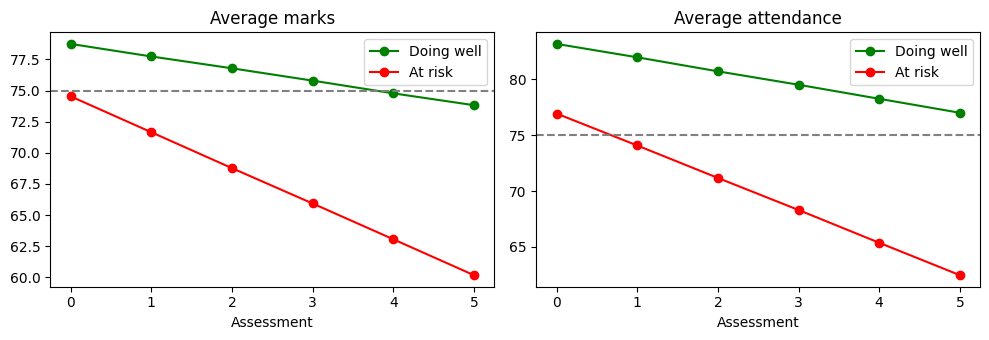

In [ ]:
plt.figure(figsize=(10, 3.5))
for k, (name, col) in enumerate([('Doing well', 'green'), ('At risk', 'red')]):
    plt.subplot(1, 2, 1); plt.plot(avg_marks[y == k].mean(axis=0), label=name, color=col, marker='o')
    plt.subplot(1, 2, 2); plt.plot(avg_att[y == k].mean(axis=0),   label=name, color=col, marker='o')
for i, title in [(1, 'Average marks'), (2, 'Average attendance')]:
    plt.subplot(1, 2, i); plt.axhline(75, ls='--', color='gray'); plt.title(title); plt.xlabel('Assessment'); plt.legend()
plt.tight_layout(); plt.show()

## Step 4 — Prepare the input (feature engineering)
1. **Join** marks and attendance → 20 numbers per assessment (10 marks + 10 attendance).
2. **Add "change" features** → how much each value has changed since the *first* assessment (negative = falling). This helps the CNN see the trend → now **40 numbers** per assessment.
3. **Scale** everything from 0–100 to **0–1** so the network trains easily.
4. **Split** into train (80%) and test (20%).

In [ ]:
values = np.concatenate([marks, attendance], axis=2)        # shape (N, 6, 20)
change = values - values[:, :1, :]                          # change since 1st assessment
X = np.concatenate([values, change], axis=2) / 100.0        # shape (N, 6, 40)
print('Input shape:', X.shape, '-> (students, assessments, 40 features)')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Input shape: (2000, 6, 40) -> (students, assessments, 40 features)
Train: (1600, 6, 40) | Test: (400, 6, 40)


## Step 5 — Build the CNN (only 1 convolution layer!)
- `Conv1D` slides over the 6 assessments and learns patterns like "marks are dropping".
- `Flatten` turns the result into one long row.
- `Dense(2, softmax)` is the **output layer: 2 neurons** → `[doing well, at risk]`.

In [ ]:
model = keras.Sequential([
    keras.layers.Input(shape=(T, 4 * S)),                   # 6 assessments x 40 features
    keras.layers.Conv1D(8, kernel_size=3, activation='relu'),  # the only hidden layer
    keras.layers.Flatten(),
    keras.layers.Dense(2, activation='softmax')             # output: 2 neurons
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4, 8)           │           968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,034 (4.04 KB)

 Trainable params: 1,034 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6 — Compile and train
**Hyperparameters** (you choose these): `EPOCHS`, `BATCH_SIZE`, learning rate.
The network learns its **parameters** (weights) using backpropagation.

In [ ]:
EPOCHS = 30
BATCH_SIZE = 32

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',   # labels are 0 or 1
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                    validation_split=0.2, verbose=2)

Epoch 1/30


40/40 - 1s - 21ms/step - accuracy: 0.6922 - loss: 0.5951 - val_accuracy: 0.7281 - val_loss: 0.5309


Epoch 2/30


40/40 - 0s - 4ms/step - accuracy: 0.7102 - loss: 0.5170 - val_accuracy: 0.7281 - val_loss: 0.4757


Epoch 3/30


...

40/40 - 0s - 8ms/step - accuracy: 0.8781 - loss: 0.2748 - val_accuracy: 0.8750 - val_loss: 0.2761


Epoch 29/30


40/40 - 0s - 4ms/step - accuracy: 0.8789 - loss: 0.2721 - val_accuracy: 0.8750 - val_loss: 0.2734


Epoch 30/30


40/40 - 0s - 4ms/step - accuracy: 0.8820 - loss: 0.2699 - val_accuracy: 0.8781 - val_loss: 0.2711


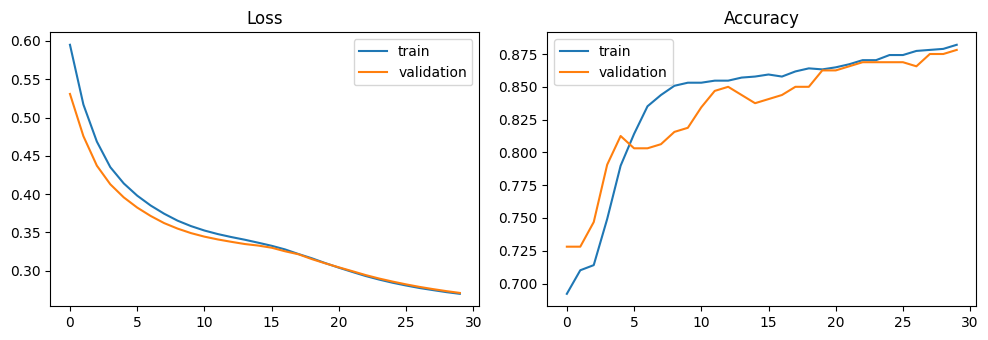

In [ ]:
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(history.history['loss'], label='train'); plt.plot(history.history['val_loss'], label='validation'); plt.title('Loss'); plt.legend()
plt.subplot(1, 2, 2); plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='validation'); plt.title('Accuracy'); plt.legend()
plt.tight_layout(); plt.show()

## Step 7 — Test on unseen students

In [ ]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test accuracy: {acc:.2%}')

Test accuracy: 85.50%


## Step 8 — Predict for a new student

In [ ]:
def check_student(student_marks, student_att):
    """Both inputs have shape (6, 10): 6 assessments x 10 subjects, values in %."""
    values = np.concatenate([student_marks, student_att], axis=1)   # (6, 20)
    x = np.concatenate([values, values - values[:1, :]], axis=1) / 100.0   # add change features -> (6, 40)
    out = model.predict(x[None, :, :], verbose=0)[0]        # 2 numbers
    print(f'Output: [doing well = {out[0]:.2f}, at risk = {out[1]:.2f}]')
    print('AT RISK of falling behind' if out.argmax() == 1 else 'Student is doing well')

t = np.arange(T)[:, None]

print('Student 1: marks 85 -> 60, attendance 90 -> 60')
check_student(85 - 5 * t + np.zeros((T, S)), 90 - 6 * t + np.zeros((T, S)))

print('\nStudent 2: marks and attendance steady')
check_student(82 + np.zeros((T, S)), 90 + np.zeros((T, S)))

print('\nStudent 3: marks falling but attendance is fine')
check_student(85 - 5 * t + np.zeros((T, S)), 92 + np.zeros((T, S)))

Student 1: marks 85 -> 60, attendance 90 -> 60
Output: [doing well = 0.03, at risk = 0.97]
AT RISK of falling behind

Student 2: marks and attendance steady
Output: [doing well = 0.99, at risk = 0.01]
Student is doing well

Student 3: marks falling but attendance is fine


Output: [doing well = 0.95, at risk = 0.05]
Student is doing well


### Summary (for viva)
- **Input:** 6 assessments × 40 features (10 marks + 10 attendance + their changes), scaled to 0–1
- **Model:** Conv1D(8) → Flatten → Dense(2, softmax)
- **Loss:** sparse categorical cross-entropy | **Optimizer:** Adam
- **Output:** 2 neurons → doing well / at risk